# Tâche A1 — 1.1 Nettoyage de la feuille *Logements*

**Projet d'économétrie appliquée** · Consommation d'énergie et rénovation thermique · Responsable : Membre 1

**Objectif (Gantt A1)** : copie brute conservée, anomalies documentées, données propres et effectif final.

**Démarche**
1. Charger la feuille `Logements` et conserver une copie brute.
2. Contrôles de structure (types, valeurs manquantes, doublons, modalités).
3. Repérer valeurs impossibles / aberrantes / codes de non-réponse (min, max, histogrammes, consommation par m²).
4. Pour chaque anomalie : explication et traitement (correction ou suppression).
5. Sauvegarder `data/processed/logements_propres.csv` et le journal des anomalies.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Chemins portables : fonctionne depuis la racine du dépôt ou depuis notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw" / "donnees_energie.xlsx"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figures"
TAB = ROOT / "outputs" / "tables"
for p in (PROC, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("Racine du projet :", ROOT)

Racine du projet : /home/claude/econometrie-energie


## 1. Chargement et copie brute

In [2]:
brut = pd.read_excel(RAW, sheet_name="Logements")
brut.to_csv(PROC / "logements_brut.csv", index=False)   # copie brute (avant tout nettoyage), réutilisée en 3.2
print("Dimensions brutes :", brut.shape)
brut.head()

Dimensions brutes : (2000, 29)


,ID,Conso_kWh,Surface_m2,Nb_occupants,Maison,Annee_construction,Chauffage,DJU,Revenu_kEUR,Proprietaire,Age_referent,Teletravail_jours,Piscine,Voiture_electrique,Climatisation,Seche_linge,Congelateur,Ballon_electrique,Panneaux_solaires,Thermostat_connecte,Lave_vaisselle,Nb_ecrans,Animal_compagnie,Jardin,Velo,Abonnement_streaming,Renovation,Cheque_renovation,Artisans_RGE
0,1,8710.0,99,3,1,1997,PAC,2357,30.0,0,36,2,0,0,0,1,0,0,0,0,0,1,1,1,0,1,0,1,4.4
1,2,33405.0,144,5,1,1957,Electrique,2256,130.1,1,68,0,0,0,0,1,1,1,0,0,1,5,1,1,0,0,1,0,8.2
2,3,11548.0,115,3,0,2005,Gaz,2199,16.4,0,33,0,0,0,1,1,0,0,0,0,0,7,0,0,0,1,0,0,4.4
3,4,15841.0,73,1,1,1983,Electrique,2570,26.8,0,49,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,1,1,9.2
4,5,15723.0,78,3,1,2009,Bois,2619,47.7,1,70,0,1,0,0,0,0,0,0,0,0,5,1,1,0,0,1,1,3.5


## 2. Contrôles de structure

In [3]:
print("Valeurs manquantes (NaN) :", int(brut.isna().sum().sum()))
print("ID dupliqués            :", int(brut["ID"].duplicated().sum()))
print("Lignes entièrement dupliquées :", int(brut.duplicated().sum()))
print()
print("Modalités de Chauffage :")
print(brut["Chauffage"].value_counts(dropna=False).to_string())

binaires = ["Maison", "Proprietaire", "Piscine", "Voiture_electrique", "Climatisation", "Seche_linge",
            "Congelateur", "Ballon_electrique", "Panneaux_solaires", "Thermostat_connecte", "Lave_vaisselle",
            "Animal_compagnie", "Jardin", "Velo", "Abonnement_streaming", "Renovation", "Cheque_renovation"]
hors = {c: int((~brut[c].isin([0, 1])).sum()) for c in binaires}
print("\nVariables binaires hors {0,1} :", {k: v for k, v in hors.items() if v} or "aucune")

Valeurs manquantes (NaN) : 0
ID dupliqués            : 0
Lignes entièrement dupliquées : 0

Modalités de Chauffage :
Chauffage
Gaz           801
Electrique    797
PAC           220
Bois          130
Fioul          52

Variables binaires hors {0,1} : aucune


Aucune valeur manquante *explicite* : les non-réponses sont donc **codées par une valeur** (ex. `9999`).
Il faut les chercher dans les minimums / maximums.

## 3. Repérage des anomalies

### 3.1 Minimum, maximum et valeurs extrêmes

In [4]:
quanti = ["Conso_kWh", "Surface_m2", "Nb_occupants", "Annee_construction", "DJU", "Revenu_kEUR",
          "Age_referent", "Teletravail_jours", "Nb_ecrans", "Artisans_RGE"]
resume = brut[quanti].describe(percentiles=[.01, .5, .99]).T[["min", "1%", "50%", "99%", "max"]]
resume

,min,1%,50%,99%,max
Conso_kWh,7.6,4082.620,13424.0,43807.040,70298.0
Surface_m2,15.0,32.000,89.0,209.040,9999.0
Nb_occupants,1.0,1.000,3.0,6.000,7.0
Annee_construction,1880.0,1882.990,1976.0,2022.000,2023.0
DJU,1300.0,1607.690,2400.0,3252.150,3600.0
Revenu_kEUR,9.0,13.499,37.4,118.614,211.1
Age_referent,22.0,22.000,52.0,86.000,90.0
Teletravail_jours,0.0,0.000,0.0,5.000,5.0
Nb_ecrans,0.0,0.000,3.0,8.010,12.0
Artisans_RGE,0.5,1.500,7.4,13.200,15.9


In [5]:
brut["Conso_par_m2"] = brut["Conso_kWh"] / brut["Surface_m2"]
print("Surface_m2 — 5 plus grandes valeurs :", sorted(brut["Surface_m2"].nlargest(5).tolist()))
print("Conso_kWh  — 6 plus petites valeurs  :", brut["Conso_kWh"].nsmallest(6).tolist())
print()
print("Valeurs de Surface_m2 >= 500 :")
print(brut.loc[brut["Surface_m2"] >= 500, ["ID", "Surface_m2", "Conso_kWh", "Maison", "Nb_occupants"]].to_string(index=False))
print()
print("Valeurs de Conso_kWh < 1000 :")
print(brut.loc[brut["Conso_kWh"] < 1000, ["ID", "Conso_kWh", "Surface_m2", "Chauffage", "Conso_par_m2"]].to_string(index=False))

Surface_m2 — 5 plus grandes valeurs : [279, 282, 288, 9999, 9999]
Conso_kWh  — 6 plus petites valeurs  : [7.6, 10.2, 18.0, 2901.0, 3131.0, 3197.0]

Valeurs de Surface_m2 >= 500 :
  ID  Surface_m2  Conso_kWh  Maison  Nb_occupants
 354        9999    13464.0       0             3
1914        9999    10378.0       1             4

Valeurs de Conso_kWh < 1000 :
  ID  Conso_kWh  Surface_m2  Chauffage  Conso_par_m2
 315       18.0          55        Gaz      0.327273
1050        7.6          69 Electrique      0.110145
1559       10.2          92 Electrique      0.110870


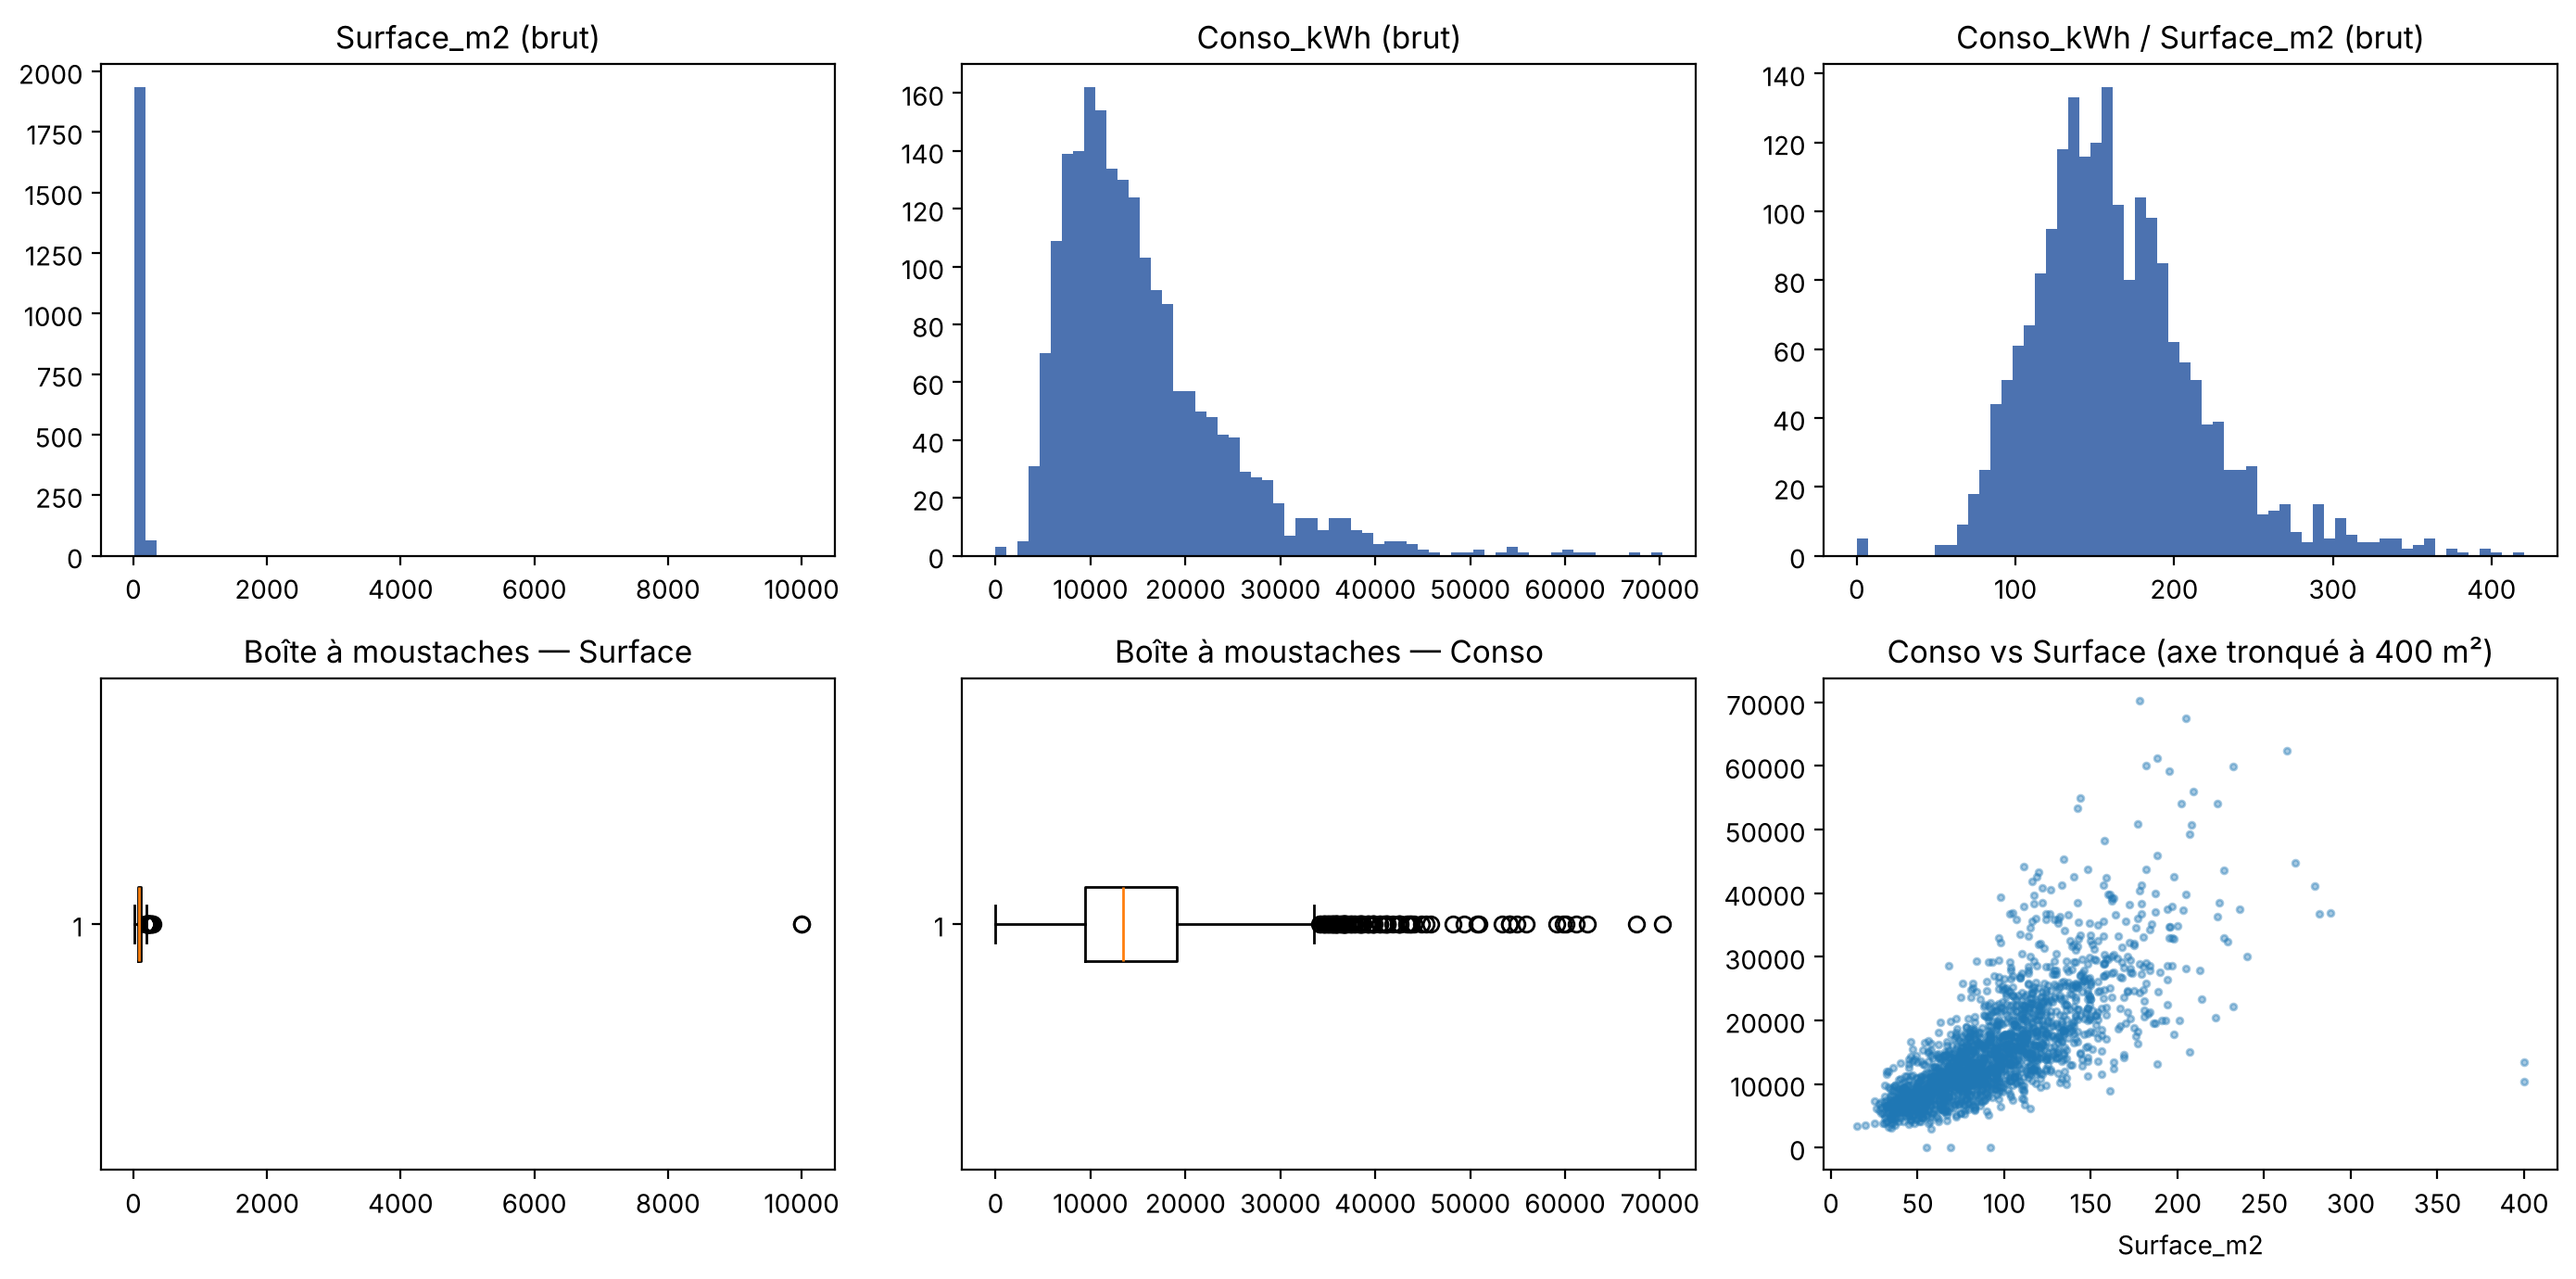

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
ax[0, 0].hist(brut["Surface_m2"], bins=60, color="#4C72B0");  ax[0, 0].set_title("Surface_m2 (brut)")
ax[0, 1].hist(brut["Conso_kWh"], bins=60, color="#4C72B0");   ax[0, 1].set_title("Conso_kWh (brut)")
ax[0, 2].hist(brut["Conso_par_m2"], bins=60, color="#4C72B0"); ax[0, 2].set_title("Conso_kWh / Surface_m2 (brut)")
ax[1, 0].boxplot(brut["Surface_m2"], orientation="horizontal");  ax[1, 0].set_title("Boîte à moustaches — Surface")
ax[1, 1].boxplot(brut["Conso_kWh"], orientation="horizontal");   ax[1, 1].set_title("Boîte à moustaches — Conso")
ax[1, 2].scatter(brut["Surface_m2"].clip(upper=400), brut["Conso_kWh"], s=6, alpha=.4)
ax[1, 2].set_title("Conso vs Surface (axe tronqué à 400 m²)"); ax[1, 2].set_xlabel("Surface_m2")
plt.tight_layout(); plt.savefig(FIG / "a1_anomalies_avant_nettoyage.png", dpi=150); plt.show()

**Lecture.** Deux familles d'anomalies ressortent :

- **`Surface_m2 = 9999`** : valeur sentinelle, aucune surface habitable réelle ne s'en approche (le maximum « normal » est 288 m²). C'est un **code de non-réponse**. La consommation par m² de ces lignes (≈ 1 kWh/m²) confirme l'absurdité.
- **`Conso_kWh` entre 7 et 18** : consommation annuelle de quelques kWh pour un logement de 55 à 92 m² — impossible (consommation par m² ≈ 0,1–0,3 kWh/m² contre 50–420 pour le reste de l'échantillon). Le rapport au reste de l'échantillon est d'environ 1/1000 : **erreur d'unité (MWh saisis au lieu de kWh)**.

### 3.2 Contrôle de plausibilité de l'hypothèse « MWh »

In [7]:
susp = brut.loc[brut["Conso_kWh"] < 1000, ["ID", "Conso_kWh", "Surface_m2"]].copy()
susp["Conso_x1000"] = susp["Conso_kWh"] * 1000
susp["kWh_par_m2_apres_x1000"] = (susp["Conso_x1000"] / susp["Surface_m2"]).round(1)
bornes = brut.loc[brut["Conso_kWh"] >= 1000].eval("Conso_kWh / Surface_m2")
bornes = bornes[brut.loc[brut["Conso_kWh"] >= 1000, "Surface_m2"] < 9999]
print(f"Reste de l'échantillon : conso/m² de {bornes.min():.0f} à {bornes.max():.0f} kWh/m² (médiane {bornes.median():.0f})")
susp

Reste de l'échantillon : conso/m² de 50 à 421 kWh/m² (médiane 157)


,ID,Conso_kWh,Surface_m2,Conso_x1000,kWh_par_m2_apres_x1000
314,315,18.0,55,18000.0,327.3
1049,1050,7.6,69,7600.0,110.1
1558,1559,10.2,92,10200.0,110.9


Après multiplication par 1000, les trois lignes retombent dans l'intervalle observé : l'hypothèse d'une erreur d'unité est cohérente. On corrige plutôt que de supprimer (on garde l'information et on évite de perdre des observations).

### 3.3 Autres contrôles de plausibilité

In [8]:
controles = pd.DataFrame({
    "contrôle": [
        "Annee_construction > 2025", "Age_referent < 18", "Nb_occupants < 1",
        "Teletravail_jours hors [0,5]", "Revenu_kEUR <= 0", "DJU <= 0", "Artisans_RGE < 0",
        "Surface_m2 < 10", "Nb_ecrans < 0",
    ],
    "nb de lignes": [
        (brut["Annee_construction"] > 2025).sum(), (brut["Age_referent"] < 18).sum(), (brut["Nb_occupants"] < 1).sum(),
        (~brut["Teletravail_jours"].between(0, 5)).sum(), (brut["Revenu_kEUR"] <= 0).sum(), (brut["DJU"] <= 0).sum(),
        (brut["Artisans_RGE"] < 0).sum(), (brut["Surface_m2"] < 10).sum(), (brut["Nb_ecrans"] < 0).sum(),
    ],
})
controles

,contrôle,nb de lignes
0,Annee_construction > 2025,0
1,Age_referent < 18,0
2,Nb_occupants < 1,0
3,"Teletravail_jours hors [0,5]",0
4,Revenu_kEUR <= 0,0
5,DJU <= 0,0
6,Artisans_RGE < 0,0
7,Surface_m2 < 10,0
8,Nb_ecrans < 0,0


In [9]:
# Valeurs « plafonnées » ou « planchers » (censure) — à signaler, mais ce ne sont pas des erreurs de saisie
censures = pd.DataFrame({
    "variable": ["Age_referent", "Annee_construction", "DJU", "DJU", "Revenu_kEUR"],
    "valeur": [90, 1880, 1300, 3600, 9.0],
    "nb de lignes": [(brut["Age_referent"] == 90).sum(), (brut["Annee_construction"] == 1880).sum(),
                     (brut["DJU"] == 1300).sum(), (brut["DJU"] == 3600).sum(), (brut["Revenu_kEUR"] == 9.0).sum()],
})
print("Revenu_kEUR : 5 plus grandes valeurs =", brut["Revenu_kEUR"].nlargest(5).tolist())
censures

Revenu_kEUR : 5 plus grandes valeurs = [211.1, 174.3, 164.6, 164.2, 154.6]


,variable,valeur,nb de lignes
0,Age_referent,90.0,9
1,Annee_construction,1880.0,4
2,DJU,1300.0,2
3,DJU,3600.0,1
4,Revenu_kEUR,9.0,4


**Décision sur les valeurs extrêmes « légitimes ».** Quelques valeurs sont regroupées sur une borne (âge 90, année 1880, DJU 1300/3600, revenu 9 k€) : il s'agit vraisemblablement de **bornes de simulation / de saisie** (plafonnement). Elles restent dans des plages plausibles : **on les conserve** et on les signale dans le rapport. La queue de droite du revenu (jusqu'à 211 k€) et de la consommation (jusqu'à 70 298 kWh) est cohérente avec une distribution asymétrique ; on **ne supprime pas** ces observations (une logique d'écart à la médiane supprimerait de l'information réelle). Leur influence sera étudiée en 3.2 (levier, distance de Cook).

## 4. Traitement et journal des anomalies

In [10]:
propre = brut.drop(columns="Conso_par_m2").copy()
journal = []

# --- Anomalie 1 : Surface_m2 = 9999 (code de non-réponse) -> NaN puis suppression
masque_surface = propre["Surface_m2"] == 9999
for _, r in propre.loc[masque_surface].iterrows():
    journal.append({"ID": int(r["ID"]), "variable": "Surface_m2", "valeur_brute": 9999,
                    "diagnostic": "Code de non-réponse (valeur sentinelle)", "traitement": "Suppression de la ligne",
                    "valeur_apres": np.nan})
propre.loc[masque_surface, "Surface_m2"] = np.nan
propre = propre.dropna(subset=["Surface_m2"]).copy()

# --- Anomalie 2 : Conso_kWh < 100 (erreur d'unité MWh -> kWh) -> correction x1000
masque_conso = propre["Conso_kWh"] < 100
ids_corriges = propre.loc[masque_conso, "ID"].tolist()
for _, r in propre.loc[masque_conso].iterrows():
    journal.append({"ID": int(r["ID"]), "variable": "Conso_kWh", "valeur_brute": r["Conso_kWh"],
                    "diagnostic": "Erreur d'unité probable (MWh saisis au lieu de kWh)", "traitement": "Correction ×1000",
                    "valeur_apres": r["Conso_kWh"] * 1000})
propre.loc[masque_conso, "Conso_kWh"] = propre.loc[masque_conso, "Conso_kWh"] * 1000

journal = pd.DataFrame(journal)
journal.to_csv(TAB / "a1_journal_anomalies.csv", index=False)
journal

,ID,variable,valeur_brute,diagnostic,traitement,valeur_apres
0,354,Surface_m2,9999.0,Code de non-réponse (valeur sentinelle),Suppression de la ligne,NaN
1,1914,Surface_m2,9999.0,Code de non-réponse (valeur sentinelle),Suppression de la ligne,NaN
2,315,Conso_kWh,18.0,Erreur d'unité probable (MWh saisis au lieu de...,Correction ×1000,18000.0
3,1050,Conso_kWh,7.6,Erreur d'unité probable (MWh saisis au lieu de...,Correction ×1000,7600.0
4,1559,Conso_kWh,10.2,Erreur d'unité probable (MWh saisis au lieu de...,Correction ×1000,10200.0


In [11]:
# Vérifications après nettoyage
propre["Conso_par_m2"] = propre["Conso_kWh"] / propre["Surface_m2"]
print("Observations brutes   :", len(brut))
print("Lignes supprimées     :", len(brut) - len(propre))
print("Valeurs corrigées     :", len(ids_corriges), "(ID", ids_corriges, ")")
print("Observations conservées :", len(propre))
print(f"Conso/m² après nettoyage : min {propre['Conso_par_m2'].min():.0f}, max {propre['Conso_par_m2'].max():.0f} kWh/m²")
print(f"Surface après nettoyage  : min {propre['Surface_m2'].min():.0f}, max {propre['Surface_m2'].max():.0f} m²")
assert propre.isna().sum().sum() == 0 and propre["ID"].is_unique
propre = propre.drop(columns="Conso_par_m2")
propre.to_csv(PROC / "logements_propres.csv", index=False)

Observations brutes   : 2000
Lignes supprimées     : 2
Valeurs corrigées     : 3 (ID [315, 1050, 1559] )
Observations conservées : 1998
Conso/m² après nettoyage : min 50, max 421 kWh/m²
Surface après nettoyage  : min 15, max 288 m²


## 5. Avant / après nettoyage

In [12]:
avant_apres = pd.concat({
    "avant": brut[["Conso_kWh", "Surface_m2"]].describe().T[["count", "mean", "std", "min", "max"]],
    "après": propre[["Conso_kWh", "Surface_m2"]].describe().T[["count", "mean", "std", "min", "max"]],
}, axis=1).round(1)
avant_apres.to_csv(TAB / "a1_avant_apres.csv")
avant_apres

avant                                   après                                  
             count     mean     std   min      max   count     mean     std     min      max
Conso_kWh   2000.0  15448.8  8749.4   7.6  70298.0  1998.0  15470.2  8735.2  2901.0  70298.0
Surface_m2  2000.0    104.1   315.7  15.0   9999.0  1998.0     94.1    40.0    15.0    288.0

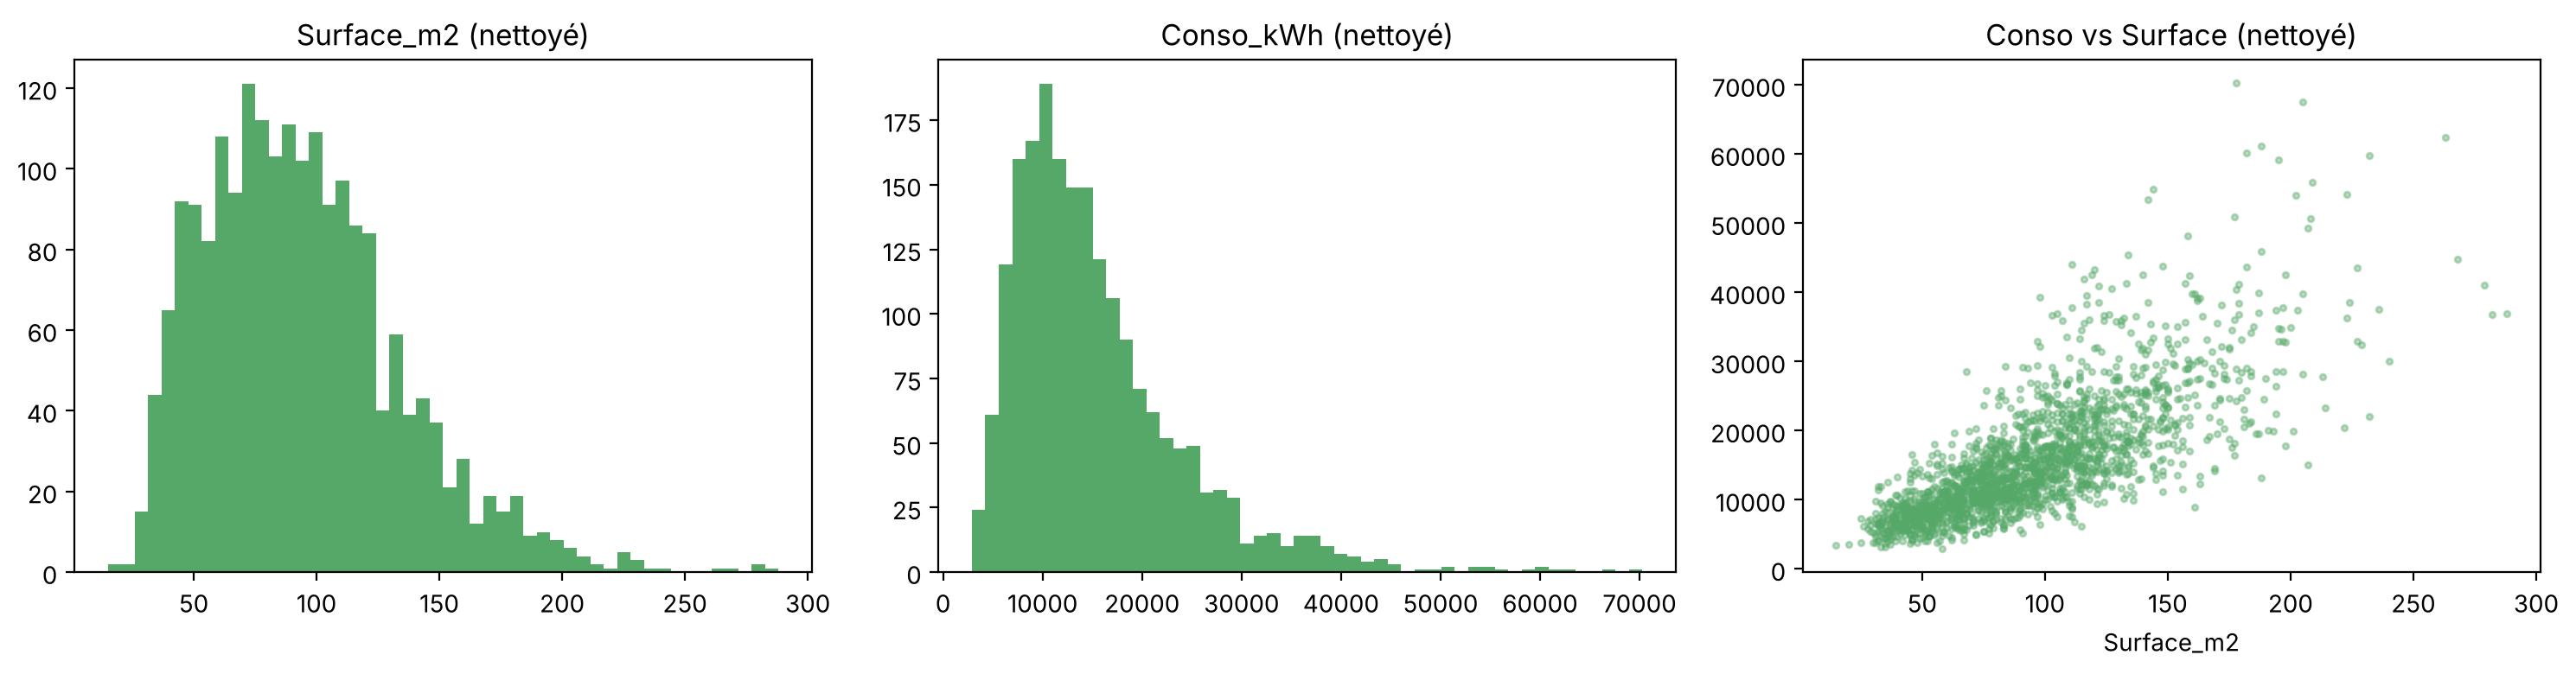

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(propre["Surface_m2"], bins=50, color="#55A868"); ax[0].set_title("Surface_m2 (nettoyé)")
ax[1].hist(propre["Conso_kWh"], bins=50, color="#55A868");  ax[1].set_title("Conso_kWh (nettoyé)")
ax[2].scatter(propre["Surface_m2"], propre["Conso_kWh"], s=6, alpha=.4, color="#55A868")
ax[2].set_title("Conso vs Surface (nettoyé)"); ax[2].set_xlabel("Surface_m2")
plt.tight_layout(); plt.savefig(FIG / "a1_apres_nettoyage.png", dpi=150); plt.show()

## 6. Sensibilité : correction ×1000 ou suppression des trois consommations ?

In [14]:
alt = brut.drop(columns="Conso_par_m2")
alt = alt[(alt["Surface_m2"] != 9999) & (alt["Conso_kWh"] >= 100)]          # suppression au lieu de correction
res = {}
for nom, df in {"Correction ×1000 (retenu)": propre, "Suppression des 3 lignes": alt}.items():
    m = smf.ols("Conso_kWh ~ Surface_m2", data=df).fit()
    res[nom] = {"N": int(m.nobs), "beta0": m.params["Intercept"], "beta1 (kWh/m²)": m.params["Surface_m2"],
                "R²": m.rsquared}
pd.DataFrame(res).T.round(3)

,N,beta0,beta1 (kWh/m²),R²
Correction ×1000 (retenu),1998.0,-272.974,167.217,0.586
Suppression des 3 lignes,1995.0,-280.682,167.296,0.586


Les deux traitements donnent un coefficient de surface quasi identique : le choix n'est pas déterminant pour les résultats. On retient la **correction** (effectif plus élevé, information conservée).

## 7. Synthèse pour le rapport (partie 1.1)

In [15]:
print(f"""
- Observations brutes : {len(brut)} ; conservées : {len(propre)} (2 lignes supprimées, 3 valeurs corrigées).
- Surface_m2 = 9999 (ID {journal.loc[journal.variable=='Surface_m2','ID'].tolist()}) : code de non-réponse -> suppression.
- Conso_kWh < 100 (ID {ids_corriges}) : erreur d'unité MWh/kWh -> correction ×1000.
- Valeurs plafonnées (âge 90, année 1880, DJU 1300/3600, revenu 9 k€) et queues de distribution : conservées.
- Fichier produit : data/processed/logements_propres.csv ; journal : outputs/tables/a1_journal_anomalies.csv.
- Copie brute : data/processed/logements_brut.csv (à réutiliser en 3.2 pour la sensibilité aux erreurs de saisie).
""")


- Observations brutes : 2000 ; conservées : 1998 (2 lignes supprimées, 3 valeurs corrigées).
- Surface_m2 = 9999 (ID [354, 1914]) : code de non-réponse -> suppression.
- Conso_kWh < 100 (ID [315, 1050, 1559]) : erreur d'unité MWh/kWh -> correction ×1000.
- Valeurs plafonnées (âge 90, année 1880, DJU 1300/3600, revenu 9 k€) et queues de distribution : conservées.
- Fichier produit : data/processed/logements_propres.csv ; journal : outputs/tables/a1_journal_anomalies.csv.
- Copie brute : data/processed/logements_brut.csv (à réutiliser en 3.2 pour la sensibilité aux erreurs de saisie).

